# Аналитический отчёт по итоговому проекту
**Исследовательский вопрос:** Как цена и рейтинг книг в каталоге `books.toscrape.com` соотносятся с их библиографическими характеристиками (годом первого издания и числом изданий) по данным Open Library в разрезе категорий?

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
conn = sqlite3.connect('db/warehouse.db')
df = pd.read_sql_query('SELECT * FROM mart_books_enriched', conn)
cat_df = pd.read_sql_query('SELECT * FROM mart_category_summary', conn)
runs_df = pd.read_sql_query('SELECT * FROM pipeline_runs', conn)
conn.close()

print('Всего книг в витрине:', len(df))
print('Обогащено через Open Library:', int(df['is_enriched'].sum()))
display(cat_df.head(15))
display(runs_df)

Всего книг в витрине: 1000
Обогащено через Open Library: 154


,category,books_count,avg_price_gbp,avg_rating,enriched_count,avg_first_publish_year,avg_edition_count
0,Default,152,34.39,2.84,0,NaN,NaN
1,Nonfiction,110,34.26,2.88,2,2016.0,5.0
2,Sequential Art,75,34.57,2.97,14,2011.9,4.8
3,Add a comment,67,35.80,2.76,0,NaN,NaN
4,Fiction,65,36.07,3.18,45,2005.6,22.8
5,Young Adult,54,35.45,3.30,0,NaN,NaN
6,Fantasy,48,39.59,3.08,0,NaN,NaN
7,Romance,35,33.93,2.63,9,2013.4,4.0
8,Mystery,32,31.72,2.94,9,2004.1,13.9
9,Food and Drink,30,31.41,2.90,0,NaN,NaN


,run_id,started_at,finished_at,status,quality_verdict,books_collected,books_clean,books_rejected,api_enriched
0,20261124T075955Z,2026-11-24T07:59:55.048444+00:00,2026-11-24T08:03:36.882637+00:00,SUCCESS,RED,1000,1000,0,137
1,20261124T080420Z,2026-11-24T08:04:20.237171+00:00,2026-11-24T08:04:56.836537+00:00,SUCCESS,RED,0,1000,0,148
2,20261124T081314Z,2026-11-24T08:13:14.424441+00:00,2026-11-24T08:13:50.411266+00:00,SUCCESS,GREEN,0,1000,0,154
3,20261124T082612Z,2026-11-24T08:26:12.755006+00:00,2026-11-24T08:26:57.822635+00:00,DEGRADED_CIRCUIT_BREAKER,GREEN,0,1000,0,154


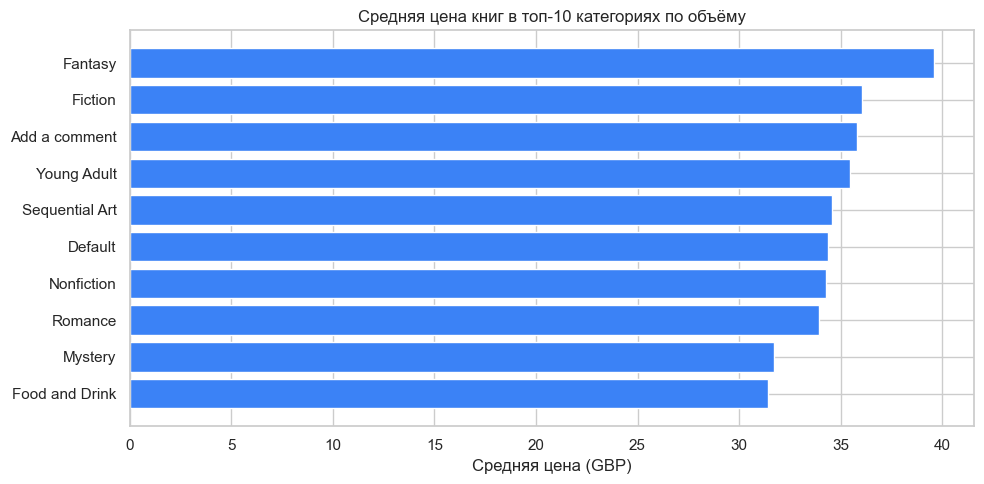

In [2]:
# График 1: Распределение средней цены по топ-10 категориям
top10 = cat_df.head(10).sort_values('avg_price_gbp', ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(top10['category'], top10['avg_price_gbp'], color='#3b82f6')
plt.xlabel('Средняя цена (GBP)')
plt.title('Средняя цена книг в топ-10 категориях по объёму')
plt.tight_layout()
plt.show()

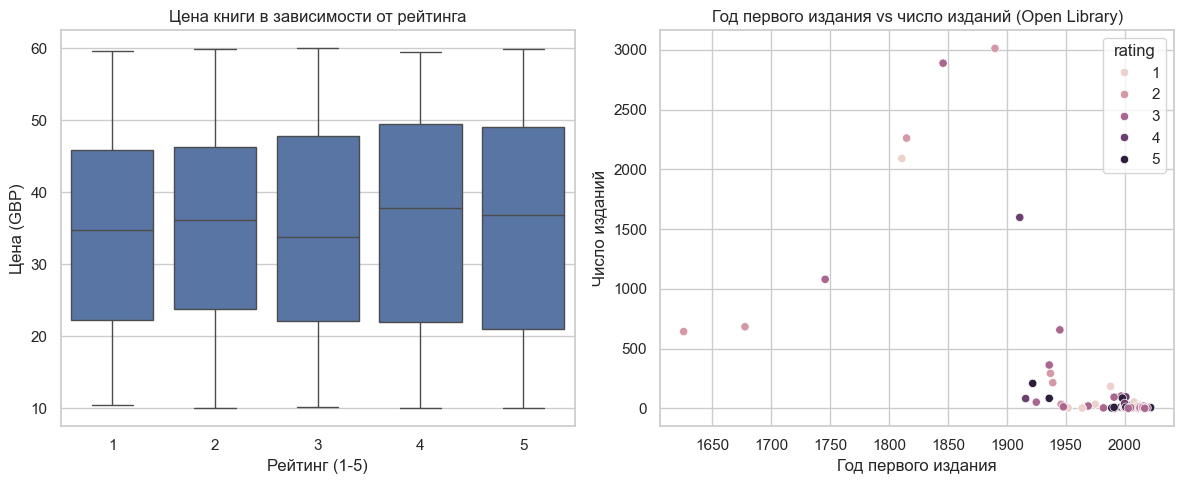

In [3]:
# График 2: Связь цены, рейтинга и числа изданий (для обогащённых книг)
enriched = df[df['is_enriched'] == 1].dropna(subset=['first_publish_year', 'edition_count'])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x='rating', y='price_gbp', ax=axes[0])
axes[0].set_title('Цена книги в зависимости от рейтинга')
axes[0].set_xlabel('Рейтинг (1-5)')
axes[0].set_ylabel('Цена (GBP)')

sns.scatterplot(data=enriched, x='first_publish_year', y='edition_count', hue='rating', ax=axes[1])
axes[1].set_title('Год первого издания vs число изданий (Open Library)')
axes[1].set_xlabel('Год первого издания')
axes[1].set_ylabel('Число изданий')
plt.tight_layout()
plt.show()

## Выводы и ограничения

1. **Связь цены и рейтинга:** по всему каталогу (1000 книг) выраженной зависимости между рейтингом (1–5 звёзд) и ценой нет — медианные цены и межквартильный размах на графике (boxplot) практически одинаковы для всех уровней рейтинга. Это подтверждает синтетический характер ценообразования на учебной площадке `books.toscrape.com`.
2. **Различия по категориям:** среди топ-10 крупнейших категорий самая высокая средняя цена зафиксирована в категории **Fantasy** (£39.59, средний рейтинг 3.08), а самая низкая — в **Food and Drink** (£31.41, рейтинг 2.90) и **Mystery** (£31.72, рейтинг 2.94). Среди топ-15 категорий максимальный средний рейтинг у **Poetry** (3.53), а минимальный — у **Classics** (2.47).
3. **Библиографические характеристики (Open Library):** из 1000 книг обогащено 154 (15,4%). Наиболее контрастно выделяется категория **Classics** (16 обогащённых книг): средний год первого издания — **1906.4**, а среднее число изданий — **947.4**, что на порядок превышает показатели современных жанров, таких как **Fiction** (год 2005.6; 22.8 изданий), **Childrens** (год 2010.5; 16.6 изданий), **Sequential Art** (год 2011.9; 4.8 изданий) и **Romance** (год 2013.4; 4.0 изданий). На диаграмме рассеяния видно, что классические произведения XIX — начала XX века стабильно имеют значительно большее число переизданий.

### Ограничения исследования
* `books.toscrape.com` — учебный каталог с синтетическими ценами и рейтингами, поэтому результаты по цене/рейтингу не отражают реальный книжный рынок.
* Обогащение через Open Library выполнялось с порогом сходства названий `match_score >= 0.6` и ограничением числа запросов за прогон (`max_titles_per_run`), поэтому охват составил 15,4% (154 из 1000 книг), а в ряде категорий (`Default`, `Young Adult`, `Fantasy` и др.) обогащённые записи отсутствуют.
* Данные представляют собой срез на дату сбора (24.11.2026).
